# Onsets and tempo

`OnsetStrength` gives the rectified spectral flux of log-magnitude spectra per frame, `OnsetRate` the number of onsets
per second of a chunk, and `Tempo` the tempo of a chunk (BPM), from the autocorrelation of the onset strength.
(`BeatTrack` gives beat and downbeat positions with the [beat_this](https://github.com/CPJKU/beat_this) model, and
needs to download its checkpoint : it is not shown here.)

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from acids_dataset import features as F

SR = 22050
DURATION = 6.
torch.manual_seed(0)

def drums(bpm, swing=0., duration=DURATION):
    """kicks on beats, hi-hats on off-beats (delayed by swing, as a ratio of a beat)."""
    x = torch.zeros(int(duration * SR))
    beat = 60 / bpm
    kick_t = torch.arange(int(0.15 * SR)) / SR
    kick = torch.sin(2 * math.pi * 60 * kick_t * (1 + 2 * torch.exp(-kick_t * 40))) * torch.exp(-kick_t * 25)
    hat = torch.randn(int(0.03 * SR)) * torch.exp(-torch.arange(int(0.03 * SR)) / 100) * 0.3
    for k in range(int(duration / beat) + 1):
        for start, sound in [(k * beat, kick), ((k + 0.5 + swing) * beat, hat)]:
            i = int(start * SR)
            if i < len(x):
                n = min(len(sound), len(x) - i)
                x[i:i + n] += sound[:n]
    return 0.5 * x[None]

## Onset strength

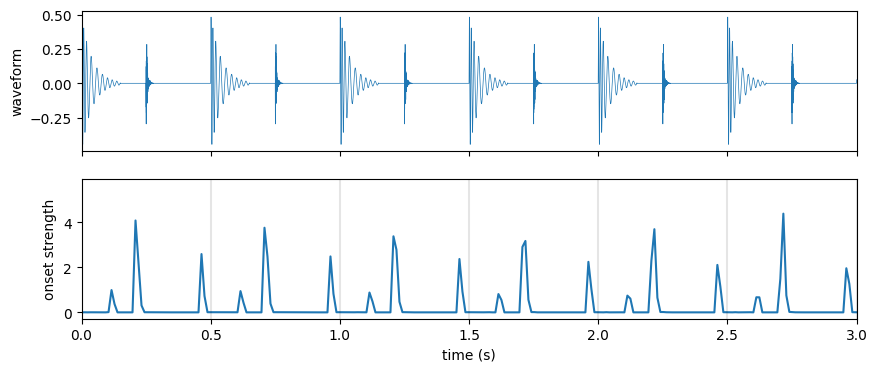

In [2]:
x = drums(120)
onset = F.OnsetStrength(sr=SR)(x)                 # hop_length = 256 by default
times = torch.arange(len(onset)) * 256 / SR

fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
axes[0].plot(torch.arange(x.shape[-1]) / SR, x[0], lw=0.5); axes[0].set_ylabel("waveform")
axes[1].plot(times, onset); axes[1].set_ylabel("onset strength"); axes[1].set_xlabel("time (s)")
for b in torch.arange(0, DURATION, 0.5):
    axes[1].axvline(b, color="k", alpha=0.1)
axes[0].set_xlim(0, 3); plt.show()

## Onset rate and tempo

With kicks and hats, we expect 2 onsets per beat. `OnsetRate` picks peaks of the onset strength above `threshold`
(and at least `min_interval` apart) : it is an approximate count, that can be tuned with these parameters.

`Tempo` uses a log-normal prior around `prior_bpm` (120 BPM, with width `prior_width` in octaves), that resolves octave
ambiguities (60 / 120 / 240 BPM). Note the octave error at 70 BPM : 140 BPM is closer to the prior.

In [3]:
print("%6s %22s %10s" % ("bpm", "onsets / s (expected)", "tempo"))
for bpm in [70, 90, 110, 128, 150, 174]:
    x = drums(bpm)
    print("%6d %14.2f (%.2f) %10.1f" % (bpm, F.OnsetRate(sr=SR)(x).item(), 2 * bpm / 60, F.Tempo(sr=SR)(x).item()))

   bpm  onsets / s (expected)      tempo
    70           3.00 (2.33)      139.9
    90           3.50 (3.00)       90.0
   110           3.50 (3.67)      110.0
   128           4.17 (4.27)      128.1
   150           4.83 (5.00)      150.1
   174           5.67 (5.80)      173.9


The prior matters for ambiguous rhythms : a fast groove at 160 BPM can also be felt at half tempo (80 BPM). A narrow
prior chooses the octave :

In [4]:
x = drums(160)
for prior in [80, 160]:
    print("prior %d BPM -> %.1f BPM" % (prior, F.Tempo(prior_bpm=prior, prior_width=0.3, sr=SR)(x).item()))

prior 80 BPM -> 80.0 BPM
prior 160 BPM -> 160.1 BPM


Per-chunk descriptors like `Tempo` and `OnsetRate` can be used to balance datasets or to build stratified partitions
(see the dataset notebook). In a dataset of chunks, each chunk gets its own value :

In [5]:
long = torch.cat([drums(90, duration=4.), drums(140, duration=4.)], -1)
chunks = long.unfold(-1, 2 * SR, 2 * SR).transpose(0, 1)           # (4, 1, 2 s)
print("tempo of 2 s chunks :", F.Tempo(sr=SR).batch_call(chunks).flatten())

tempo of 2 s chunks : tensor([ 89.9977,  89.9933, 139.8656, 139.9780])
